# Q2 data extraction

<br>
<br>


<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


**Author(s):** Manon Gilles (Exoplanet Team, IAP, France),<br>
with inputs from Henry Joy McCracken, Clotilde Laigle, 
<br>the help of the VIS team, and the Exoplanet Team of IAP.

<br>
This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.
<br>
<br>

**Last modified:** 2026-02-24

**Notebook summary**

Euclid is an ESA mission launched on July 1st 2023, with the prime goal of mapping the dark matter distribution in the Universe. Meanwhile, motivated by the upcoming Nancy Grace Roman Galactic Bulge Time Domain Survey (GBTDS), ESA approved a dedicated microlensing
observation program. On the March 23rd 2025, Euclid changed pointing direction and conducted a 24-hour campaign of the Galactic Bulge.  The campaign covers all the future NASA Nancy Grace Roman fields in addition to 8081 historical events from ground-based microlensing surveys. The Euclid Galactic Bulge Survey (EGBS) constitutes the largest high-resolution Galactic Bulge survey to date dedicated to the study of exoplanets via gravitational microlensing. The list of the Q2 data release products and scientific papers can be found here: 
https://www.cosmos.esa.int/web/euclid/q2-data-release

The Q2 data products contain the 16 calibrated dithers, 400 second exposure each, of the nine Galactic Bulge fields acquired by Euclid. In addition, there are 16 dithers of 400 second of exposure of the PSF reference frames that were used to construct the Q2 EGBS PSF model using PSFex. Finally, we provide the calibrated source catalogues produced using the standard Q1 PSF model, as described in: http://st-dm.pages.euclid-sgs.uk/data-product-doc/dm10/visdpd/dpcards/vis_calibratedquadframe.html

To facilitate the users we also provide an extraction tool that creates cutout frames centered on the desired RA, DEC (or galactic) coordinates. The users can obtain a cutout, with the size of their choice, of the calibrated scientific frames, the background, flag and signal-to-noise ratio maps in addition to the PSF model for each dither.

This notebook will guide you through the **EuclidExtractor** code and give you some informations on the Euclid Galactic Bulge Survey (EGBS) data. The commands needed to use it in the terminal are explained in the last part of this notebook.

The EGBS data were acquired between March 23 and 24, 2025, during a one-time survey of the Galactic Bulge.


Data explanation:

- EUC_VIS_SWL-BKG-{obsid}-{dither}-{expnum}_*.fits  
  background image of the corresponding calibrated frame, generated by GnuAstro
  NoiseChisel.

- EUC_VIS_SWL-DET-{obsid}-{dither}-{expnum}_*_sci.fits  
  science image of the calibrated frame

- EUC_VIS_SWL-DET-{obsid}-{dither}-{expnum}_*_flg.fits  
  flag map of the calibrated frame

- EUC_VIS_SWL-DET-{obsid}-{dither}-{expnum}_*_rms.fits  
  noise map of the calibrated frame. It contains the quadratic sum of the image
  photon noise (square root of the science image) and the readout noise.

- EUC_VIS_SWL-WGT-{obsid}-{dither}-{expnum}_*.fits  
  VIS calibrated exposure weight map. It's the master PRNU image with all
  invalid pixels set to 0.

The scientific data has an observation identifier **obsid = 067070**. The other data used to calculate the PSF has an identifier obsid = 067068 / 067071.  
The exposure number is always the same, **expnum = 1**. It usually changes for Euclid data, but not for EGBS data, which only has a single 400 s exposure. 

Each field was observed 16 times at 4 slightly different positions, each observed 4 times.  
It is possible to determine the field of observation based on the dither number. As illustrated in the image below: 
- 0:15 -> field 1
- 16:31 -> field 2
- 32:47 -> field 3
- 48:63 -> field 4
- 64:79 -> field 5
- 80:95 -> field 6
- 96:111 -> field 7
- 112:127 -> field 8
- 128:143 -> field 9

In the images folder there is an plot of the field locations (image credit: Euclid VIS team):

<img src="images/EGBS.Footprint_with_fields.png" width="600">

Each field (a focal-plane array) is divided into 144 quadrants (36 CCDs, each made of 4 quadrants), as shown in the image at (image credit: *"Euclid Quick Data Release (Q1) : VIS processing and data products (Euclid Collaboration: H. J. McCracken et al. 2025)"*):

<img src="images/quadrants.png" width="400">

**Some useful links:**
* [Euclid Q2 data product description](https://www.cosmos.esa.int/web/euclid/q2-data-release)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Astroquery.Euclid documentation content](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)
* [Astroquery.EuclidClass help content](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass)
* [Astropy table documentation](https://docs.astropy.org/en/stable/table/index.html)
* Q1 VIS processing and data products (Euclid Collaboration: [H. J. McCracken et al. 2025](https://ui.adsabs.harvard.edu/abs/2025arXiv250315303E/abstract))

**Running the notebook:**

* This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. Please note that the links to the images displayed above might break when the notebook is copied. The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.

***

In [1]:
from euclid_extractor import EuclidCutoutExtractor, EuclidPSFExtractor
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.io import fits
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, PercentileInterval, AsinhStretch, SqrtStretch, SquaredStretch
import matplotlib.pyplot as plt
import numpy as np
import os

%matplotlib inline

In [2]:
data_dir   = '/media/home/data/euclid_q2/egbs-v1/data' # Data files location
output_dir = '/media/user/example_notebook_outputs/cutouts/'

# Making a folder for the output files
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

## Target choice

The cell below specifies the target coordinates. It uses the [Astropy.Skycoord](https://docs.astropy.org/en/stable/api/astropy.coordinates.SkyCoord.html) package to read coordinates in several formats and translate them to degrees.

In [3]:
ra = '17:52:07.49'
dec = '-29:50:46.0'

c               = SkyCoord(f"{ra} {dec}", unit=(u.hourangle, u.deg))
ra_deg, dec_deg = c.ra.deg, c.dec.deg

## Cutouts extraction

The code below initialises the "EuclidCutoutExtractor" - the core software in this tutorial.

In ESA Datalabs, one may read the SQLite database path (**euclid_index.db**) directly from the Euclid Q2 folder, as in the example below. In this case, use **rebuild_index=False**.

In case you are running this Jupyter Notebook outside of ESA Datalabs, you would need to recreate it and store it locally. Please change the **db_path='euclid_index.db'** and use the argument **rebuild_index=True**.

In [4]:
extractor = EuclidCutoutExtractor(
    data_dir,                   # data directory where the Euclid calibrated frames are stored 
    db_path='/data/user/euclid_q2/egbs-v1/EuclidExtractor/euclid_index.db',  # base SQLite database path (the adresses of the data files)
    rebuild_index=False          # whether to rebuild the index or use the existing one    
    
    #in case you are running this script outside ESA Datalabs uncomment the next two lines, and comment the previous two
    #db_path='euclid_index.db',  # base SQLite database path (the adresses of the data files)
    #rebuild_index=True        # rebuild the index
)

Using existing index: /data/user/euclid_q2/egbs-v1/EuclidExtractor/euclid_index.db


### Step 1: Find associated extensions

The first step consists in finding the extensions where the target is present. The results are stored in a Python dictionary, that contains the following items: 
- the filename of the quadrant in the calibrated frames ; 
- the name of the quadrant (ex : 1-1.E) ; 
- the target position in the quadrant in pixels, in x ('x_center') and y ('y_center') directions ;
- the length of the quadrant in pixels in the x ('nx') and in the y ('ny') direction.

The example below displays the items for the first match.

In [5]:
matches = extractor.find_extensions(ra_deg, dec_deg)
print(f"The target is present in {len(matches)} quadrants. \n First match details: \n")

match_0 = matches[0]
for key in match_0:
    print(f'  * {key}: {match_0[key]}')

The target is present in 16 quadrants. 
 First match details: 

  * filename: /media/home/data/euclid_q2/egbs-v1/data/EUC_VIS_SWL-DET-067070-80-1__20250621T164446.982391Z_sci.fits
  * extension: 1-2.F.SCI
  * x_center: 1643.395321227832
  * y_center: 1779.5994723000194
  * nx: 2048
  * ny: 2066


### Step 2: Extract the cutouts from the pre-selected extensions

The code below extracts the cutouts from the quadrants where the target was found. The cutouts are saved as (single extension) FITS files inside the *output_dir*, and their file name follows this convention:
"output_dir/{prefix}_ ra{ra}_ dec{dec}_ ccd{cdd number}_ quad{letter E/F/G/H}_ {dither number 0:143}_ {data type}.fits"

Four different files ("science", "rms" "flag", and "background") are generated for each cutout.



**Note:**

It is a good idea to also extract the PNG images to ensure the orientation of the FITS file.

In [6]:
outs = extractor.extract_cutout(
    ra_deg,
    dec_deg,
    size_arcsec=60,              # size in arcsec (--size), default is 60 arcsec
    include_rms=True,            # include rms cutout (--rms)
    include_flg=True,            # include flg curtout (--flg)
    output_dir=output_dir,       # output directory (--outdir)
    prefix="cutout",             # prefix for output files (--prefix)
    debug_wcs=False,             # debug wcs (--debug-wcs)
    create_png_sci=True,         # include png of science cutout (--png-sci)
    create_png_rms=True,         # include png of rms cutout (--png-rms)
    create_png_flg=True,         # include png of flag cutout (--png-flg)
    size_rmsflg=60               # size of rms and flg cutout in arcsec (--size-rmsflg), default is 25 arcsec
)

Found 16 extension(s)
[1/16] EUC_VIS_SWL-DET-067070-80-1__20250621T164446.982391Z_sci.fits[1-2.F.SCI]
  ✓ SCI → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_sci.fits
  ✓ RMS → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_rms.fits
  ✓ FLG → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_flg.fits
  ✓ BKG → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_bkg.fits
[2/16] EUC_VIS_SWL-DET-067070-81-1__20250621T165746.968373Z_sci.fits[1-2.G.SCI]
  ✓ SCI → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadG_81_sci.fits
  ✓ RMS → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadG_81_rms.fits
  ✓ FLG → /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadG_81_flg.fits
  ✓ BKG → /media/use

In [7]:
cutout_index = 0 # There are four files per cutout - change this index by multiples of 4, e.g., "0, 4, 8, ..."

hdul = []
tags = []
for jj in range(4):
    fits_file = outs[cutout_index + jj]
    print(f'* Reading: {fits_file}')
    tags.append(fits_file[fits_file.rfind('_')+1:fits_file.rfind('.')])
    hdul.append(fits.open(fits_file))

* Reading: /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_sci.fits
* Reading: /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_rms.fits
* Reading: /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_flg.fits
* Reading: /media/user/example_notebook_outputs/cutouts/cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_bkg.fits


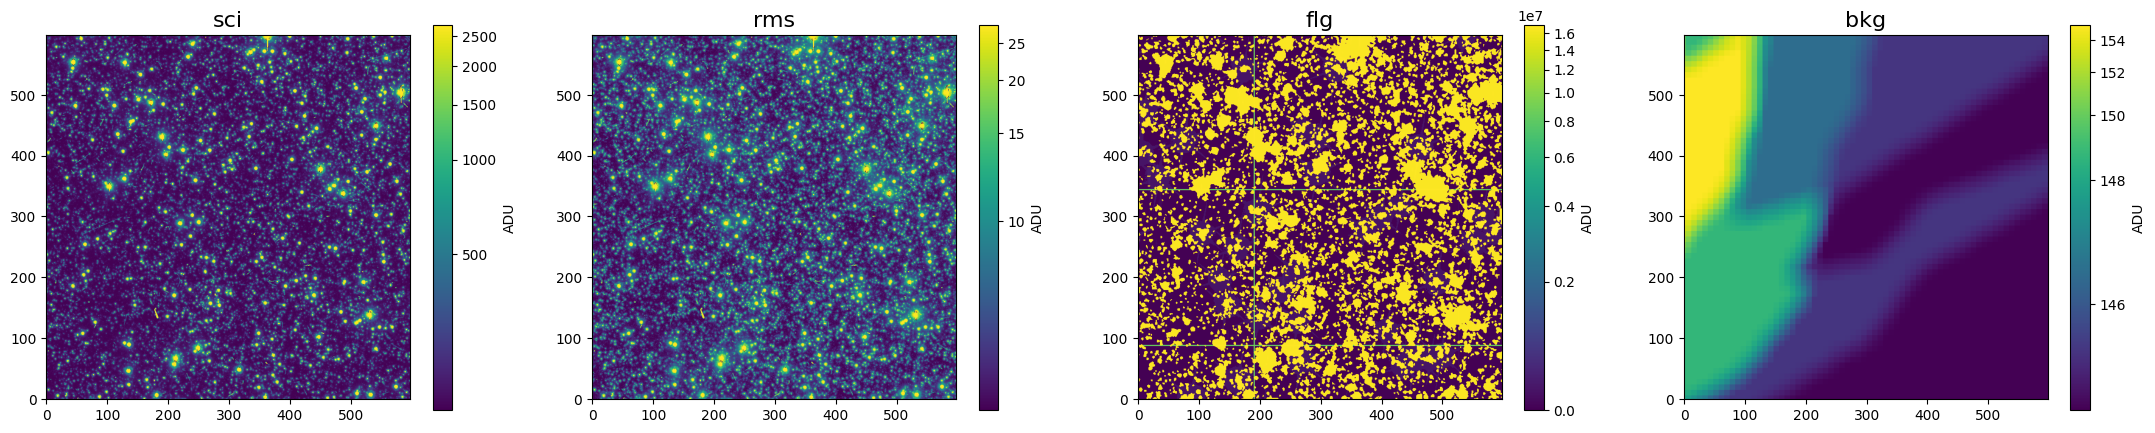

In [14]:
fig = plt.figure(figsize=[27,5])

for ii in range(4):
    plt.subplot(1,4,ii+1)
    hdu      = hdul[ii][0]
    img_data = hdu.data
    plt.imshow(img_data, cmap='viridis', origin='lower', norm=ImageNormalize(img_data, interval=PercentileInterval(97.5), stretch=AsinhStretch()))
    plt.colorbar(label = hdu.header['BUNIT'])
    plt.title(tags[ii], fontsize = 16)
plt.show()

## PSF Extraction

This part of the notebook uses the "EuclidPSFExtractor" code.

First, we define the location of the PSF file. This file was generated with PSFEx. The resulting PSF is a 21x21 array that can be calculated for different options.

In [15]:
psf_file = "/media/home/data/euclid_q2/egbs-v1/PSFEx_model/EUC_VIS_MDL-PSF_250323-250324_20251010T191512.440105Z.psf"

### Step 1: Find the PSFs associated to each cutout

There are three different PSFs: one computed for the target coordinates, another computed for the target quadrant, and an average PSF for all quadrants. The code below stores the PSFs in a Pandas dataframe, where the PSFs are sorted following the order of the input cutouts.

In [16]:
psf_extractor = EuclidPSFExtractor(psf_file)
matched_psfs = psf_extractor.psfs_for_matches(
    matches,        # list of matches from find_extensions
    RA=ra_deg, 
    DEC=dec_deg,  
    p_radec=True,   # calculate the PSF at the target RA,DEC
    p_quad=True,    # calculate the average PSF in the target quadrant
    p_all=True      # calculate the average PSF for the entire detector
)
matched_psfs

,filename,extension,quad,psf ra/dec,psf quadrant,psf all quadrants,x position,y position
0,cutout_ra268.031208_dec-29.846111_ccd1-2_quadF...,1-2.F,6,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0778435...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0778435...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1643.3953,1779.5995
1,cutout_ra268.031208_dec-29.846111_ccd1-2_quadG...,1-2.G,7,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0880431...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0880431...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1031.2526,812.2473
2,cutout_ra268.031208_dec-29.846111_ccd1-2_quadG...,1-2.G,7,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.9201996...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.9201996...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1024.3399,1919.4534
3,cutout_ra268.031208_dec-29.846111_ccd2-2_quadF...,2-2.F,30,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.7888229...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.7888229...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",420.9944,320.8313
4,cutout_ra268.031208_dec-29.846111_ccd1-2_quadF...,1-2.F,6,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.1422630...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.1422630...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1641.3025,1791.8021
5,cutout_ra268.031208_dec-29.846111_ccd1-2_quadG...,1-2.G,7,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.9984904...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.9984904...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1031.8100,814.7972
6,cutout_ra268.031208_dec-29.846111_ccd1-2_quadG...,1-2.G,7,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.7806043...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.7806043...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1025.6807,1919.3363
7,cutout_ra268.031208_dec-29.846111_ccd2-2_quadF...,2-2.F,30,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.1570491...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.1570491...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",420.2566,318.0678
8,cutout_ra268.031208_dec-29.846111_ccd1-2_quadF...,1-2.F,6,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0329630...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0329630...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1640.5541,1793.2696
9,cutout_ra268.031208_dec-29.846111_ccd1-2_quadG...,1-2.G,7,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.8918565...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.8918565...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.2089866...",1032.3718,814.4674


To save the dataframe in the cutouts directory:

In [17]:
matched_psfs.to_pickle(output_dir + "PSFs.pkl")

### Step 2: Extract the PSF associated to one cutout and display them

The example below displays the PSFs associated to the first cutout (as this is the one displayed above).

In [18]:
row = matched_psfs.loc[cutout_index]

* Plotting PSFs for file: cutout_ra268.031208_dec-29.846111_ccd1-2_quadF_80_sci.fits; extension = 1-2.F


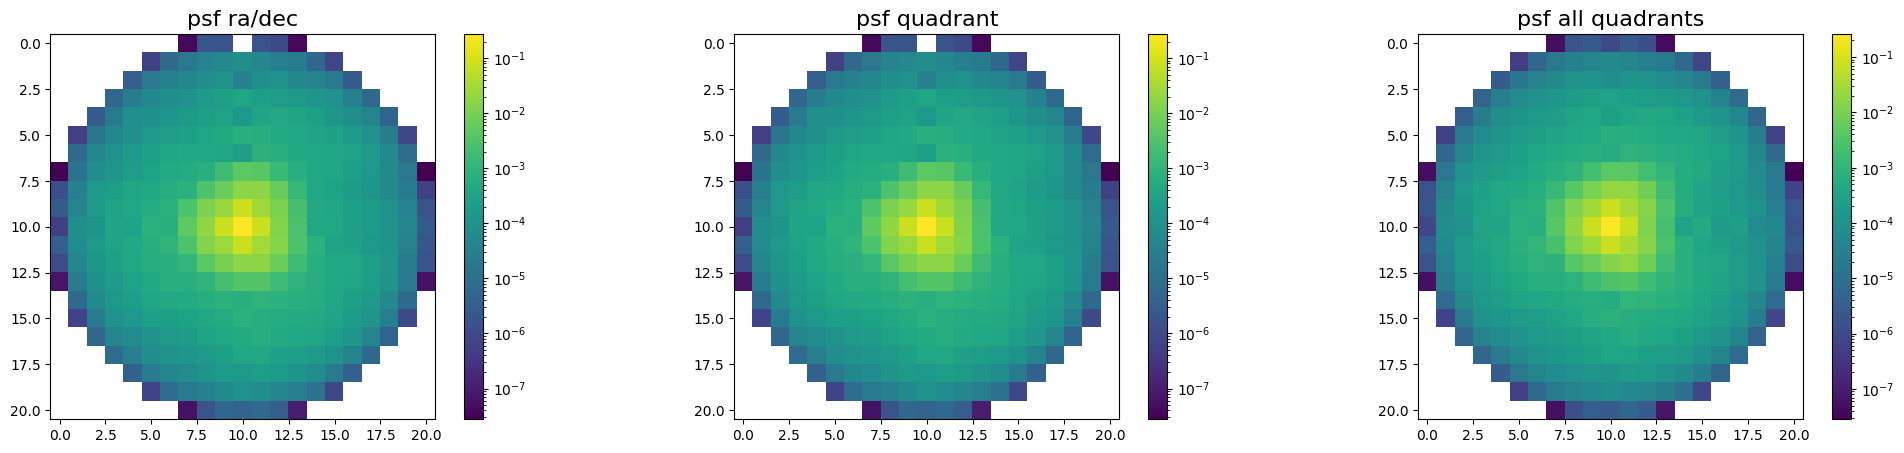

In [19]:
print(f"* Plotting PSFs for file: {row['filename']}; extension = {row['extension']}")

fig  = plt.figure(figsize=[25,5])
keys = ['psf ra/dec', 'psf quadrant', 'psf all quadrants']

for zz in range(3):
    plt.subplot(1,3,1 + zz)
    plt.imshow(row[keys[zz]], norm='log')
    plt.title(keys[zz], fontsize = 16)
    plt.colorbar()

plt.show()

# How to call EuclidExtractor from a terminal

The commands to run EuclidExtractor from the terminal are explained below.

**python euclid_extractor.py data_dir --ra 267.14 --dec=-29.98 -s 100 --rms --flg -o output_dir --prefix prefix --rebuild-index --db-path db-path --png-sci --png-rms --png-flg --psf-radec --psf-quad --psf-all**

data_dir : calibrated data directory

--ra 267.14 : right ascension in hours:minutes:seconds or degrees

--dec=-29.98 : : declination in hours:minutes:seconds or degrees

-s 100 : size of the cutout

--rms : include the rms files

-- flg : include the flg files

-o output_dir : output directory

--prefix prefix : prefix used in the cutouts name

--rebuild-index : create the spatial-index database to explore the calibrated frames, it needs to be done every time the code is runned in a different folder

--db-path db-path : spatial-index database name to explore the calibrated frames

--png-sci : include png of sci data cutouts

--png-rms : include png of rms data cutouts

--png-flg : include png of flg data cutouts

--size-rmsflg : size of the rms and flg cutouts

--psf-radec : calculate the psf at the target ra/dec 

--psf-quad : calculate the average psf of the target quadrant 

--psf-all : calculate the average psf on all quadrants